# Do CV-parser errors reach the selection? A fairness audit of the Adecco reverse matching

**AI Ethics, Module 2 – Hiring CV Bias** · Francesco Baiocchi, Leonardo Petrilli

**Where this study comes from.** In the Hiring CV Bias project we studied a proprietary parser that extracts skills
from anonymized CVs for Adecco. After cleaning the CVs and the parser output (`data_cleaning`), we looked for
imbalances between demographic groups in the extracted skills (`distributions_analysis`) and measured the parser's
errors directly (`bias_detection`): rule-based extractors for driving licenses and language skills, and exact and
semantic matching for job titles, found information that is in the CV text but missing from the parser output, and
compared the miss rates across gender and macro-region. Those false negatives are the starting point here.

**The question.** A parser error matters only if it changes a decision. Adecco's *reverse matching* takes a job
offer and ranks the candidates by a match score computed from the parsed profile. This study asks whether the parser's
errors reach that ranking, and whether they do so unevenly across groups.

* **RQ1** – Do the errors of the CV parser propagate to the selection on the job offers, and do they penalize some
  groups (gender, macro-region, women of the South) more than others?
* **RQ2** – Does correcting the parser work as a fairness mitigation, compared with the standard techniques
  (reweighing, in-processing, post-processing)?
* **RQ3** – Which pieces of information drive the effect, and how robust are the conclusions to our choices?

**Pipeline under study**

```
CV ──parser──► profile ──matcher──► score for every (candidate, job) ──► position in the job's list
```

**Three versions of every candidate profile**

| version | content | role |
|---|---|---|
| **P** | the real Adecco profile (`Candidates` sheet) | validates the reconstructed matcher |
| **O** – Original | licenses, languages, job titles **only as read by the parser** | the fully automatic pipeline |
| **C** – Corrected | O + the false negatives recovered from the CV text | the pre-processing mitigation |


In [ ]:
%load_ext autoreload
%autoreload 2

import warnings

import matplotlib.pyplot as plt
import polars as pl

%matplotlib inline
warnings.filterwarnings("ignore")

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(30)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_float_precision(4)

polars.config.Config

## Phase 1 – Data and audit

### 1.1 Loading, groups and lists

`ReverseMatching.xlsx` holds 51,490 (candidate, job) pairs for 7,769 candidates and 9,310 jobs. The cleaning of the
raw CVs (`data_cleaning`) kept 7,521 candidates with a usable CV; we keep their pairs. Twenty-two pairs are exact
duplicates and are removed.

In [ ]:
from hiring_cv_bias.config import CLEANED_REVERSE_MATCHING_PATH, REVERSE_MATCHING_PATH
from hiring_cv_bias.reverse_matching.loader import dedupe_pairs
from hiring_cv_bias.utils import load_data, load_excel_sheets

raw = load_excel_sheets(
    REVERSE_MATCHING_PATH, ["ReverseMatching", "Candidates", "Jobs"]
)
pairs_all = dedupe_pairs(raw["ReverseMatching"])
clean = load_data(CLEANED_REVERSE_MATCHING_PATH)

n_raw = raw["ReverseMatching"].height
print(
    f"pairs: {n_raw} → {pairs_all.height} after removing {n_raw - pairs_all.height} duplicates"
)
print(
    f"candidates: {raw['Candidates'].height} in the file, {clean.height} with a clean CV"
)

pairs: 51490 → 51468 after removing 22 duplicates
candidates: 7769 in the file, 7521 with a clean CV


#### Sensitive attributes

The sensitive attributes are **Gender** and **Location** (macro-region) and their intersection. `Other` (106) and
`Unknown` (11) candidates are too few for group statistics and are excluded from the fairness tables.

In [ ]:
display(clean.group_by("Gender", "Location").len().sort("Gender", "Location"))

Gender,Location,len
str,str,u32
"""Female""","""CENTER""",505
"""Female""","""NORTH""",2458
"""Female""","""SOUTH""",457
"""Male""","""CENTER""",496
"""Male""","""NORTH""",2885
"""Male""","""SOUTH""",603
"""Other""","""CENTER""",22
"""Other""","""NORTH""",50
"""Other""","""SOUTH""",34


`Age_bucket` is a deterministic function of `Gender` in the Adecco file (all women 55–74, all men 25–34): it is
corrupted and is **never used**.

In [ ]:
display(clean.group_by("Gender", "Age_bucket").len().sort("Gender", "Age_bucket"))

Gender,Age_bucket,len
str,str,u32
"""Female""","""55-74""",3420
"""Male""","""25-34""",3984
"""Other""","""45-54""",106
"""Unknown""","""Unknown""",11


#### List lengths

Each row is a (candidate, job) pair, so counting the rows of each job gives the length of its list. Lists are short:
the median job has 3 candidates, and only 3,431 jobs have at least 5. Phase 2 keeps only lists with at least 5 Female
or Male candidates, because a position within a list of one or two candidates says nothing about selection.

In [ ]:
from hiring_cv_bias.reverse_matching.audit import list_lengths

display(list_lengths(pairs_all.join(clean.select("CANDIDATE_ID"), on="CANDIDATE_ID")))

jobs,median,mean,max,jobs_ge_5
i64,f64,f64,i64,i64
9238,3.0000,5.4023,109,3431


### 1.2 The score: outliers and the formula

For every pair `ReverseMatching.xlsx` gives the `match_score` and the seven components computed by Adecco, but not how
they are combined.

#### Range of the components

For each column the table gives the number of distinct values and the range. Four components are binary (0 or 1):
`Interest`, `Card_match`, `Languages_match` and `Regulated_Trainings_match`. `Distance_match` takes three values, from
0.2 to 1 (every pair is within 25 km). `match_skills` (a share, 64 values) and `Experience` (a similarity, 1,495 values)
are continuous between 0 and 1. So every component lies in [0, 1]; `match_score` goes from 2.0 to 33.8: we look at its distribution next.

In [ ]:
from hiring_cv_bias.reverse_matching.scoring import COMPONENTS

display(
    pairs_all.select(
        pl.struct(
            n_values=pl.col(c).n_unique(), min=pl.col(c).min(), max=pl.col(c).max()
        ).alias(c)
        for c in COMPONENTS + ["match_score"]
    )
    .unpivot(variable_name="column")
    .unnest("value")
)

column,n_values,min,max
str,u32,f64,f64
"""Experience""",1495,0.0000,1.0000
"""Interest""",2,0.0000,1.0000
"""Card_match""",2,0.0000,1.0000
"""Languages_match""",2,0.0000,1.0000
"""Regulated_Trainings_match""",2,0.0000,1.0000
"""match_skills""",64,0.0000,1.0000
"""Distance_match""",3,0.2000,1.0000
"""match_score""",5621,2.0030,33.7621


#### Distance bands

`Distance_match` takes only three values, but `ReverseMatching.xlsx` also gives the distance in km (`distance_km`).
Grouping the pairs by `Distance_match` shows the km range behind each value: 1 below 10 km, 0.6 from 10 to 20 km, 0.2
from 20 to 25 km. The ranges do not overlap, so `Distance_match` is a step function of the distance, and we use these
bands to recompute it in Component rules.

In [ ]:
display(
    pairs_all.group_by("Distance_match")
    .agg(
        pl.len().alias("pairs"),
        pl.col("distance_km").min().alias("km_min"),
        pl.col("distance_km").max().alias("km_max"),
    )
    .sort("Distance_match", descending=True)
)

Distance_match,pairs,km_min,km_max
f64,u32,f64,f64
1.0000,23296,0.0000,9.9998
0.6000,19603,10.0039,19.9999
0.2000,8569,20.0002,24.9987


#### Outliers

The box is narrow and most scores are below 6. A small group forms a long right tail up to 33.8. Outliers follow the
standard box-plot rule: a pair is an outlier when its score lies above the upper whisker (red dashed line: third
quartile + 1.5 × box height). The lower whisker is below the minimum score, so there are no low outliers. The second
printed line counts them: 1,110 pairs (2.2%), above 6.41, against a third quartile of 4.65. Whether they
follow the same rule as the other pairs cannot be judged from the distribution alone, so we study how the score is
built on the other 97.8% and test the outliers against the result in Exact check. We set aside the pairs only, not the
candidates.


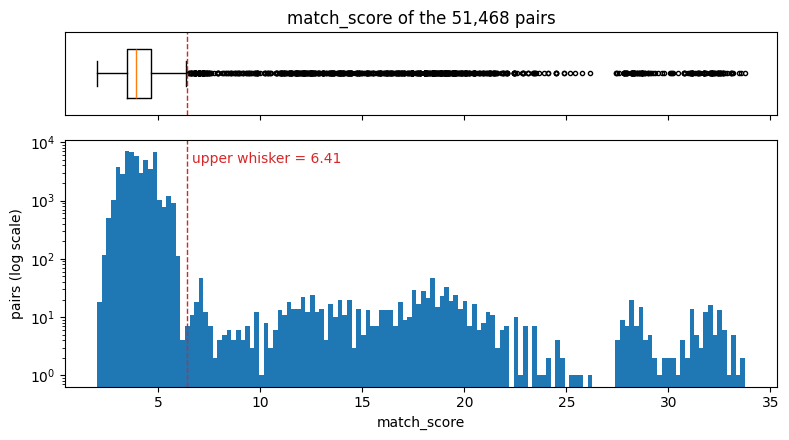

In [ ]:
from hiring_cv_bias.fairness.plots import plot_score_distribution
from hiring_cv_bias.reverse_matching.scoring import score_outliers

q1, q3 = pairs_all.select(
    pl.col("match_score").quantile(0.25).alias("q1"),
    pl.col("match_score").quantile(0.75).alias("q3"),
).row(0)
threshold = q3 + 1.5 * (q3 - q1)
is_outlier = score_outliers(pairs_all)
pairs_clean = pairs_all.filter(~is_outlier)

fig = plot_score_distribution(
    pairs_all["match_score"].to_list(),
    threshold,
    title=f"match_score of the {pairs_all.height:,} pairs",
)
plt.show()

In [ ]:
outliers = pairs_all.filter(is_outlier)
print(
    f"box: Q1 = {q1:.2f}, Q3 = {q3:.2f} | lower whisker = {q1 - 1.5 * (q3 - q1):.2f}, "
    f"minimum score = {pairs_all['match_score'].min():.2f}"
)
print(
    f"outliers: {outliers.height} pairs ({outliers.height / pairs_all.height:.1%}) above {threshold:.2f}, "
    f"in {outliers['Job_id'].n_unique()} of {pairs_all['Job_id'].n_unique()} jobs"
)

box: Q1 = 3.47, Q3 = 4.65 | lower whisker = 1.71, minimum score = 2.00
outliers: 1110 pairs (2.2%) above 6.41, in 143 of 9310 jobs


#### Weights

We start from the simplest hypothesis, a weighted sum, fitted by least squares on the pairs without outliers:

$$\text{match\_score} \approx w_0 + w_1\,\text{Experience} + w_2\,\text{Interest} + \dots + w_7\,\text{Distance\_match}$$

The estimates are almost round numbers. Rounded to one decimal:

$$\text{score} = 2\,\text{Experience} + \text{Interest} + \text{match\_skills} + \text{Distance} + 0.3\,(\text{Card} + \text{Languages} + \text{Regulated})$$

The last row is the same regression on all pairs: with the outliers, `Experience` weighs 6, `Languages_match` is
negative and the intercept is −3.3.


In [ ]:
from hiring_cv_bias.reverse_matching.scoring import fit_weights

estimated = fit_weights(pairs_clean)
weights = {k: round(v, 1) for k, v in estimated.items()}
display(
    pl.DataFrame(
        [
            {"weights": "estimated, without outliers", **estimated},
            {"weights": "rounded to one decimal", **weights},
            {
                "weights": "estimated, all pairs",
                **fit_weights(pairs_all),
            },
        ]
    )
)

weights,Experience,Interest,Card_match,Languages_match,Regulated_Trainings_match,match_skills,Distance_match,intercept
str,f64,f64,f64,f64,f64,f64,f64,f64
"""estimated, without outliers""",2.0368,0.9957,0.3001,0.2926,0.3038,0.9986,0.9954,-0.0244
"""rounded to one decimal""",2.0000,1.0000,0.3000,0.3000,0.3000,1.0000,1.0000,-0.0000
"""estimated, all pairs""",6.0832,0.8798,0.5379,-0.0922,0.5666,1.1177,0.4918,-3.3084


#### Exact check

A good fit is not enough: an approximate formula would leave a small error on every pair. So we count the scores the
rounded formula reproduces exactly (`share_exact`, error < 10⁻⁴): on the pairs without outliers it is almost all of
them, so the score *is* this formula.
The printed example recomputes one pair by hand.

The formula does not tell where the outliers come from, it only rules itself out: with every component at its maximum
of 1 it gives 2 + 1 + 1 + 1 + 3 × 0.3 = 5.9, below the outlier threshold of 6.41. So the outlier scores contain
something outside the seven components, which the data does not show, and we leave those pairs out of the study.


In [ ]:
from hiring_cv_bias.reverse_matching.scoring import validate_formula

display(validate_formula(pairs_clean, weights))

example = pairs_clean.row(0, named=True)
terms = " + ".join(f"{weights[c]:g}·{example[c]:.4f}" for c in COMPONENTS if example[c])
formula_value = sum(weights[c] * example[c] for c in COMPONENTS)
print(
    f"worked example, pair ({example['CANDIDATE_ID']}, {example['Job_id']}): "
    f"{terms} = {formula_value:.4f}; Adecco's score = {example['match_score']:.4f}"
)

n_pairs,share_exact,n_pairs_off,n_jobs_off,residual_min,residual_max
i64,f64,i64,i64,f64,f64
50358,0.9988,60,16,0.9271,3.6915


worked example, pair (6268443, ORD_999_1519): 2·0.9477 + 0.3·1.0000 + 0.3·1.0000 + 0.3·1.0000 + 1·0.6000 = 3.3955; Adecco's score = 3.3955


#### Component rules

Five of the seven components can be recomputed from two things we have: the candidate's profile and the job's
requirements (the `Jobs` sheet). For a pair:

- `Card_match`: 1 if the candidate has every driving license the job asks for, else 0.
- `Languages_match`: the same with the languages.
- `Regulated_Trainings_match`: the same with the regulated trainings, the formal qualifications a job can require (in
  the example below, a field of study).
- `match_skills`: the share of the skills the job asks for that the candidate has (`matterknowledge` in the data).
- `Distance_match`: from the distance bands above.

For the three binary components a job that asks for nothing gives 1; for `match_skills` it gives 0 (see below).

The table describes the job requirements behind these rules, one row per requirement (`req_licenses` for
`Card_match`, `req_languages` for `Languages_match`, `req_regulated` for `Regulated_Trainings_match`, `req_skills` for
`match_skills`). `share_jobs` is the share of jobs that ask for at least one item of that kind, and `example` is the
requirement of the first such job.

In [ ]:
from hiring_cv_bias.reverse_matching.components import job_requirements

jobs_req = job_requirements(raw["Jobs"])
display(
    jobs_req.select(
        pl.struct(
            share_jobs=(pl.col(c).list.len() > 0).mean(),
            example=pl.col(c).filter(pl.col(c).list.len() > 0).first().list.join("; "),
        ).alias(c)
        for c in ["req_licenses", "req_languages", "req_regulated", "req_skills"]
    )
    .unpivot(variable_name="requirement")
    .unnest("value")
)

requirement,share_jobs,example
str,f64,str
"""req_licenses""",0.3014,"""b"""
"""req_languages""",0.1589,"""francese; inglese"""
"""req_regulated""",0.0104,"""marketing"""
"""req_skills""",0.4878,"""procedure di organizzazione lo…"


To check the rules we apply them to the real profile (P) of every pair and compare the result with the value
Adecco gives in `ReverseMatching.xlsx`. The **agreement** of a component is the share of pairs where the two values are
equal. All five agree on more than 99% of the pairs, so the rules are the ones Adecco uses.

`Interest` comes from the categories the candidate selects, not from the CV: the parser does not extract it, so it is
the same in every version of the dataset. `Experience` cannot be recomputed from the data; we estimate it in 1.3.

In [ ]:
from hiring_cv_bias.reverse_matching.audit import rules_agreement
from hiring_cv_bias.reverse_matching.profiles import build_profile_real

display(rules_agreement(pairs_all, build_profile_real(raw["Candidates"]), jobs_req))

component,agreement
str,f64
"""Card_match""",0.9914
"""Languages_match""",0.9943
"""Regulated_Trainings_match""",0.9997
"""match_skills""",0.9992
"""Distance_match""",1.0000


`match_skills` needs one more choice: when a job asks for no skill the share is 0/0. The first table takes the pairs
whose job has an empty `req_skills` and counts Adecco's `match_skills`: almost all are 0, so our rule gives 0.

The second table lists the exceptions: pairs where Adecco gives a share of skills (1, 0.889, 0.5) although the `Jobs`
sheet lists no skill for the job. The values look like shares of a
real list (0.889 = 8 of 9 skills), so Adecco probably scored these jobs with a skill list that is not in our export; we
cannot check it. These pairs are part of why the agreement of `match_skills` is not 1. In P, O and C our rule gives them 0.

In [ ]:
no_skills = pairs_all.join(jobs_req.select("Job_id", "req_skills"), on="Job_id").filter(
    pl.col("req_skills").list.len() == 0
)
display(no_skills.group_by("match_skills").len().sort("match_skills"))
display(
    no_skills.filter(pl.col("match_skills") > 0)
    .select("Job_id", "CANDIDATE_ID", "match_skills")
    .sort("Job_id")
)

match_skills,len
f64,u32
0.0000,22829
0.5000,3
0.8889,2
1.0000,4


Job_id,CANDIDATE_ID,match_skills
str,i64,f64
"""ORD_16897_0126""",6011795,0.5000
"""ORD_16897_0126""",5278670,0.5000
"""ORD_16897_0126""",1396919,0.5000
"""ORD_17630_0015""",7660087,1.0000
"""ORD_17726_0064""",4086666,1.0000
"""ORD_17726_0064""",863361,1.0000
"""ORD_28945_0565""",5918129,1.0000
"""ORD_28945_0565""",4517254,0.8889
"""ORD_28945_0565""",163255,0.8889


### 1.3 Estimating `Experience` from job titles

To re-score O and C we need all seven components for each version. Six are recomputed with the rules of 1.2.
`Experience` cannot be: Adecco's documentation defines it as the "highest standardized similarity between the job
title and the candidate's experience", computed with an internal model we do not have, and the free-text job title is
not in the data either. We estimate it with the same rule, using the job category in place of the title: for each pair
the estimate is 1 if the job category appears verbatim among the candidate's titles, 0 if the candidate has no titles,
otherwise the highest cosine similarity between the category and the titles (the past job closest to the offer). The
cosine comes from a sentence encoder, a model that turns a text into a vector so that texts with a similar meaning get
similar vectors.

#### Choosing the encoder

Which encoder? On the real profile P we know Adecco's `Experience` for every pair, so we can try several and keep the
one that reproduces it best. We compare eight encoders and a string-matching baseline, all with the same rule above,
on the pairs without outliers.

The **lexical baseline** does not use any model: it only looks at the characters and the words of the two texts. It
computes two numbers and keeps the larger. The first is the share of characters the two strings have in common, in the
same order: `autista` and `autista di ambulanza` share the 7 characters of the first inside the 20 of the second, so
2 · 7 / (7 + 20) = 0.52. The second is the share of words in common: `autista` is one of the three distinct words,
0.33. The baseline gives 0.52. It is the simplest possible estimator and tells us whether an encoder adds anything over
plain string matching.

**Why multilingual encoders.** The texts are mostly Italian but not only: the parser's job titles follow an English
taxonomy and some were never translated, and the recruiters write part of the job categories in English (`sales
representative`, `cost engineer`) or in both languages (`commesso di punto vendita/shop assistant`). The table below
gives the share of texts that a language detector restricted to Italian and English reads as English, for the titles of
P (counting every occurrence) and for the job categories (one per job). An Italian-only encoder cannot see that
`warehouse worker` and `magazziniere` are the same job, so we include two Italian-only encoders in the comparison to
measure what that costs.


In [ ]:
from hiring_cv_bias.reverse_matching.experience import language_shares

pairs_P = pairs_clean.join(clean.select("CANDIDATE_ID"), on="CANDIDATE_ID")
profile_P = build_profile_real(raw["Candidates"])
titles_P = profile_P.explode("experience").drop_nulls("experience")["experience"]
display(
    pl.concat(
        [
            language_shares(titles_P.to_list()).with_columns(
                pl.lit("titles of P").alias("texts")
            ),
            language_shares(jobs_req["job_category"].to_list()).with_columns(
                pl.lit("job categories").alias("texts")
            ),
        ]
    ).pivot(on="language", index="texts", values="share")
)

texts,italian,english
str,f64,f64
"""titles of P""",0.8361,0.1639
"""job categories""",0.9509,0.0491


One title in six (16%) and one job category in twenty (5%) are English, and the mixed ones count as Italian here.

The encoders are: `MiniLM-L12` and `mpnet-base` (two multilingual sentence-transformers models trained on
paraphrases), `LaBSE` (Google's multilingual model for translation pairs), `e5-base` and `e5-large` (Microsoft's
multilingual E5 family, trained for retrieval), `bge-m3` (BAAI's multilingual retrieval model), and two Italian-only
models, `sentence-BERTino` and `sbert-italian-xxl` (Italian BERTs fine-tuned on translated sentence-similarity data).
The `parameters_M` column gives their size in millions of parameters. In the multilingual models a large part of these
parameters is the vocabulary table of the word pieces of many languages, so the size says little about the quality on
short Italian texts. The comparison is fair because all models get the same texts and the same rule, and it is the
result on P, not the size, that decides.

The other columns:

* `pearson` and `spearman` – correlation of values and of rankings with Adecco's `Experience`. The ranking is what
  matters for a position in a job's list.
* `spearman_non_verbatim` – the same ranking correlation restricted to the pairs with titles but no verbatim match, the
  only pairs where the estimator actually decides something.
* `mae` – mean absolute error. `Experience` weighs 2 in the score, so an error of e moves the score by 2e.
* `min_with_titles` – the lowest estimate among the pairs whose candidate has titles. The range of Adecco's value on
  these pairs is printed above the table: an encoder on the right scale should not go below it.
* `n_far_below` – pairs estimated below 0.4 while Adecco gives more than 0.8: gross ranking errors that no rescaling
  can fix.

The first run downloads the eight models from Hugging Face (about 6 GB); the embeddings are then cached in
`data/ethics/embeddings/`.


In [ ]:
from hiring_cv_bias.reverse_matching.build import EMBEDDINGS_DIR
from hiring_cv_bias.reverse_matching.experience import (
    candidate_estimators,
    compare_estimators,
    probe_table,
)

estimators = candidate_estimators(EMBEDDINGS_DIR)
with_titles = pairs_P.filter(pl.col("Experience") > 0)["Experience"]
print(
    f"Adecco's Experience on the {with_titles.len()} pairs with titles: "
    f"min {with_titles.min():.3f}, max {with_titles.max():.3f}"
)
display(compare_estimators(pairs_P, profile_P, jobs_req, estimators))

Adecco's Experience on the 48809 pairs with titles: min 0.829, max 1.000


estimator,parameters_M,pearson,spearman,spearman_non_verbatim,mae,min_with_titles,n_far_below
str,i64,f64,f64,f64,f64,f64,i64
"""lexical baseline""",null,0.7614,0.8058,0.6778,0.2782,0.1250,4625
"""MiniLM-L12""",118,0.7081,0.7653,0.5929,0.1355,0.2295,504
"""mpnet-base""",278,0.7586,0.8468,0.7613,0.1065,0.1997,189
"""LaBSE""",472,0.7934,0.8711,0.8119,0.1265,0.2996,253
"""e5-base""",278,0.8794,0.8971,0.8660,0.0167,0.8065,0
"""e5-large""",560,0.8596,0.8758,0.8218,0.0212,0.7649,0
"""bge-m3""",568,0.8354,0.8905,0.8523,0.1287,0.4091,0
"""it: sentence-BERTino""",68,0.8318,0.8965,0.8655,0.1366,0.1026,863
"""it: sbert-italian-xxl""",111,0.8048,0.8552,0.7802,0.1573,0.1619,818


The encoders differ a lot, and size does not explain the differences. `MiniLM-L12`, the smallest multilingual model,
ranks the pairs worse than the string baseline (Spearman 0.765 against 0.806) and gives 504 gross errors. `mpnet-base`
and `e5-base` have the same architecture and the same 278 million parameters, yet the first still puts 189 pairs near
0.2 where Adecco is above 0.8 and the second none: the difference is the training, not the size. The two largest
models do not improve on `e5-base`: `e5-large` is slightly worse on every other column, and `bge-m3` ranks almost as
well (Spearman 0.890) but on a different scale, with a lowest estimate of 0.41 and a mean absolute error of 0.129.

The Italian-only models confirm the choice of a multilingual encoder. `sentence-BERTino` ranks the pairs as well as
`e5-base` (Spearman 0.896) but with 863 gross errors, a lowest estimate of 0.10 and a mean absolute error of 0.137,
so it would need a calibration step; `sbert-italian-xxl` is worse on every column.

`e5-base` has no gross error, the highest correlations (Spearman 0.897, 0.866 on the non-verbatim pairs) and, unlike
all the others, lives on Adecco's scale: its lowest estimate on a pair with titles is 0.81, against Adecco's 0.83, and
its mean absolute error is 0.017.

The table below shows where the other encoders fail. The first five rows are short Italian titles against a longer
category that contains them: the sub-word tokenizer of MiniLM splits `autista` into `aut` + `ista` and `commesso` into
`comme` + `sso`, and the single-word vector ends up far from the compound title. These are exactly the pairs Adecco
rates around 0.9. The last two rows cross the languages.


In [ ]:
display(probe_table(estimators))

title,job_category,lexical baseline,MiniLM-L12,mpnet-base,LaBSE,e5-base,e5-large,bge-m3,it: sentence-BERTino,it: sbert-italian-xxl
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""autista""","""autista di ambulanza""",0.5185,0.2295,0.2133,0.5539,0.8870,0.8559,0.7672,0.6727,0.6987
"""commesso""","""commesso di punto vendita/shop…",0.3333,0.2509,0.6043,0.3244,0.8782,0.8791,0.5836,0.4986,0.4229
"""commesso""","""commesso di supermercato""",0.5000,0.3605,0.5759,0.4215,0.9143,0.9086,0.6766,0.7042,0.4736
"""cameriere""","""cameriere di sala""",0.6923,0.5046,0.8286,0.7638,0.9090,0.9134,0.7582,0.8474,0.8000
"""ingegnere""","""ingegnere meccanico""",0.6429,0.8499,0.9044,0.8512,0.9333,0.9415,0.8024,0.8082,0.8110
"""rappresentante di vendita""","""sales representative""",0.5778,0.8959,0.9044,0.9648,0.9075,0.9045,0.8707,0.1753,0.3371
"""warehouse worker""","""magazziniere""",0.2143,0.5310,0.5902,0.7973,0.8728,0.8634,0.6019,0.3853,0.4525


`MiniLM-L12` gives `autista` vs `autista di ambulanza` 0.23 and `commesso` vs `commesso di punto vendita/shop assistant`
0.25; `e5-base` gives 0.89 and 0.88, and even the string baseline (0.52 and 0.33) does better than MiniLM here. Across
languages the Italian-only models collapse: `rappresentante di vendita` vs `sales representative` is 0.91 for
`e5-base` and 0.18–0.34 for them, `warehouse worker` vs `magazziniere` 0.87 against 0.39–0.45.

We therefore use **`multilingual-e5-base`**. Because its cosine is already on Adecco's scale, the estimate is the
cosine itself, with no calibration step: a monotone rescaling learned on P would add a fitted component to the
pipeline without changing any ranking.

The same estimator is used for P, O and C. P also uses the *estimated* `Experience`, so the three versions are scored
in exactly the same way and differences between versions come only from the titles.

#### Building the dataset

The build step (`python -m hiring_cv_bias.reverse_matching.build`) computes the six rule-based components and the
estimated `Experience` for every pair and version and writes the result to `data/ethics/pairs.parquet`. It prints the
metrics above for the chosen encoder on P.


In [ ]:
from hiring_cv_bias.reverse_matching.build import build_dataset

result = build_dataset()
pairs = result.pairs
print(
    "Experience estimator on P:",
    {k: round(v, 3) for k, v in result.experience_diagnostics.items()},
)
print(
    f"pairs dataset: {pairs.height} rows, {pairs['CANDIDATE_ID'].n_unique()} candidates, "
    f"{pairs['Job_id'].n_unique()} jobs"
)

Experience estimator on P: {'pearson': 0.879, 'spearman': 0.897, 'spearman_non_verbatim': 0.866, 'mae': 0.017, 'min_with_titles': 0.807, 'n_far_below': 0}
pairs dataset: 48816 rows, 7517 candidates, 9180 jobs


The figure plots the estimate against Adecco's value for every pair of P whose candidate has titles. The dashed line is
the identity. The dots follow it: the pairs with a verbatim match sit at (1, 1), the others spread along the diagonal
between 0.8 and 1, with no cloud far below it. Adecco's values are rounded to a few levels (the horizontal bands), which
is the "standardized" part of its definition that we do not reproduce.


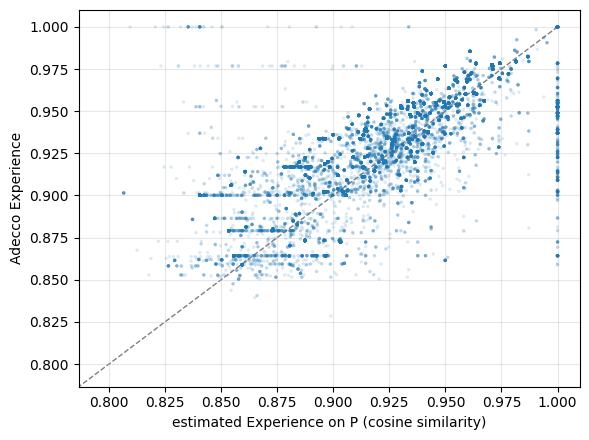

In [ ]:
from hiring_cv_bias.fairness.plots import plot_experience_estimate

fig = plot_experience_estimate(pairs)
plt.show()

### 1.4 The three profile versions

#### Fields per version

For every field and version: the mean number of items per candidate and the share of candidates with at least one
item. `regulated` and `skills` are copied from P in every version (the parser does not produce them and no false
negatives were collected for them), so they are identical across rows. From O to C the correction recovers what the
parser missed: licenses go from 28% to 59% of the candidates, languages from 88% to 98%, job titles from 91% to 95%.

In [ ]:
from hiring_cv_bias.reverse_matching.audit import profile_field_stats

profiles = result.profiles
display(profile_field_stats(profiles))

version,licenses,licenses_nonempty,languages,languages_nonempty,regulated,regulated_nonempty,skills,skills_nonempty,experience,experience_nonempty
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""P""",0.6639,0.5236,0.8639,0.4663,0.5505,0.4491,4.4052,0.4929,5.5249,0.9997
"""O""",0.3036,0.2782,1.7321,0.8787,0.5505,0.4491,4.4052,0.4929,3.0797,0.9123
"""C""",0.6184,0.5929,2.4270,0.9781,0.5505,0.4491,4.4052,0.4929,3.6510,0.9452


#### The real profile is not the parser output

If P came from the parser it would look like O; it does not (P has more licenses and fewer languages than O). The table
compares P and O candidate by candidate. The parser found a license for 2,161 candidates, but only 17% of them have any
license in P; it found languages for 6,827 candidates, 39% of whom have a language in P, and when both have one the
lists share an item in 18% of the cases. Job titles are different: almost every candidate with parsed titles has
titles in P and half of them share at least one. So `experience` comes from the parser (titles translated to Italian,
plus manually added ones: the lists are almost never identical), while licenses and languages were entered by hand: the
real matcher used a **partly manual** profile.

We do not know where the manual fields come from (a correction of the parser, or information that was never in the CV,
e.g. from an interview), so we do not use P to judge the parser: the parser's bias is measured on the Original vs
Corrected comparison only. P serves to validate the rules (1.2) and the `Experience` estimate (1.3).

**How to read the table.** For each field, we look only at candidates where the parser found something. We then ask three questions, each one about a smaller group than the one before:

1. **Does the real profile have anything in this field?** (`share_also_in_real`)
2. **If yes, do the two lists share at least one item?** (`share_common_item`)
3. **Are the two lists exactly the same?** (`share_identical`)

`candidates_parser` is the number of candidates we start from.

*Example.* The parser finds the skills `[Excel, SQL]` for a candidate:
- real profile `[]` → counts as "no" for question 1, and is left out of questions 2 and 3;
- real profile `[SQL, Python]` → yes to question 2, no to question 3;
- real profile `[SQL, Excel]` → yes to both (order does not matter).

In [ ]:
from hiring_cv_bias.reverse_matching.audit import profile_overlap

display(profile_overlap(profiles["P"], profiles["O"]))

field,candidates_parser,share_also_in_real,share_common_item,share_identical
str,i32,f64,f64,f64
"""licenses""",2161,0.1749,0.4603,0.4048
"""languages""",6827,0.3934,0.1791,0.0343
"""experience""",7088,1.0000,0.5044,0.0003


#### Differences at the pair level

The table above compares the profiles. Here we look at what those differences do to the score. For every (candidate,
job) pair we compute the components and the score with each version, then count how often the value changes. Each
column compares two versions:

- **P vs O**: the real profile against the parser output;
- **O vs C**: the parser output against the corrected profile.

A cell is the share of pairs where the value is different. For `Experience_hat` a gap of 0.01 or less counts as no change.

What the table shows:

- `Regulated_Trainings_match`, `match_skills` and `Distance_match` never change. They do not depend on what the parser
  extracts: regulated trainings and skills are copied from P, and the distance does not use the profile.
- **P vs O.** `Card_match` is different in 19% of the pairs and `Languages_match` in 13%.
  `Experience_hat` changes in 88% of the pairs and the score in 95%, because the parser's job titles are almost never
  the same as the real ones (`share_identical` in the table above).
- **O vs C.** Correcting the parser changes `Card_match` in 10% of the pairs, `Languages_match` in 6%,
  `Experience_hat` in 10%, and the score in 24%.

In [ ]:
from hiring_cv_bias.reverse_matching.audit import version_differences

display(
    pl.concat(
        [version_differences(pairs, "P", "O"), version_differences(pairs, "O", "C")]
    ).pivot(on="comparison", index="column", values="share_different")
)

column,P vs O,O vs C
str,f64,f64
"""Card_match""",0.1897,0.0954
"""Languages_match""",0.1325,0.0641
"""Regulated_Trainings_match""",0.0000,0.0000
"""match_skills""",0.0000,0.0000
"""Distance_match""",0.0000,0.0000
"""Experience_hat""",0.8815,0.0993
"""score""",0.9496,0.2412
